# Select WHACS points inside the inland buffer ring of the AoI, then sub-sample

Workflow:

1. Load the **AoI** polygon (`inputs/AoI_Polygons/AoI_NorthCarolina.shp`).
2. Load the **land** polygon (`assets/eeuu.shp`).
3. Load all **WHACS** waypoints from `assets/whacs.gpx`.
4. Build the **inland buffer ring**: `ring = (AoI − AoI.buffer(-d)) − land`.
   That keeps only the band of width `d` running *inside* the AoI boundary **and** *not on land*.
5. Select WHACS waypoints inside that ring.
6. **Sub-sample**: greedy random pick so any two chosen points are at least
   `min_spacing_m` apart, until the ring is saturated.
7. Plot and save both subsets:
   - `inputs/WHACS/NorthCarolina_whacs_ring.gpkg`    — all ring points.
   - `inputs/WHACS/NorthCarolina_whacs_selected.gpkg` — spaced sub-sample.

In [10]:
import geopandas as gpd
import matplotlib.pyplot as plt
from utils.config import CASE_DIR, PATHS, resolve

## Parameters

In [11]:
# Width of the inland buffer ring, in meters. Must be > 0: the ring is the
# band of width `buffer_distance_m` running INSIDE the AoI boundary and NOT on land.
buffer_distance_m = 5000.0

# Projected CRS used to do the buffer math (meters). UTM zone 18N covers North Carolina.
work_crs = "EPSG:32618"
geo_crs = "EPSG:4326"

assert buffer_distance_m > 0, "buffer_distance_m must be > 0 for a non-empty ring"

# Input file locations (override these here if you move the files around).
aoi_path = resolve(PATHS["aoi_file"])
land_path = resolve("assets/eeuu.shp")
whacs_path = resolve("assets/whacs.gpx")

# Output file for the filtered WHACS subset.
output_path = resolve("inputs/WHACS/NorthCarolina_whacs_selected.gpkg")

print(f"AoI    : {aoi_path}")
print(f"land   : {land_path}")
print(f"WHACS  : {whacs_path}")
print(f"output : {output_path}")

AoI    : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/inputs/AoI_Polygons/AoI_NorthCarolina.shp
land   : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/assets/eeuu.shp
WHACS  : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/assets/whacs.gpx
output : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/inputs/WHACS/NorthCarolina_whacs_selected.gpkg


## Load inputs

In [12]:
aoi_gdf = gpd.read_file(aoi_path).to_crs(geo_crs)
whacs_gdf = gpd.read_file(whacs_path, layer="waypoints").to_crs(geo_crs)

# The land file is a global dataset (~180k features). Spatially pre-filter it
# to the AoI bounding box (with a small lon/lat pad) before doing anything
# expensive: this avoids both slow unions and out-of-zone reprojection issues.
land_pad_deg = 0.5
minx, miny, maxx, maxy = aoi_gdf.total_bounds
land_gdf = gpd.read_file(
    land_path,
    bbox=(
        minx - land_pad_deg,
        miny - land_pad_deg,
        maxx + land_pad_deg,
        maxy + land_pad_deg,
    ),
).to_crs(geo_crs)

print(f"AoI    : {len(aoi_gdf)} feature(s) | crs={aoi_gdf.crs}")
print(
    f"land   : {len(land_gdf)} feature(s) (clipped to AoI bbox + {land_pad_deg} deg pad)"
)
print(f"WHACS  : {len(whacs_gdf)} waypoints | crs={whacs_gdf.crs}")
whacs_gdf.head()

AoI    : 1 feature(s) | crs=EPSG:4326
land   : 1 feature(s) (clipped to AoI bbox + 0.5 deg pad)
WHACS  : 2145 waypoints | crs=EPSG:4326


,ele,time,magvar,geoidheight,name,cmt,desc,src,link1_href,link1_text,...,sat,hdop,vdop,pdop,ageofdgpsdata,dgpsid,ogr_seapoint,ogr_latitude,ogr_longitude,geometry
0,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1902892,32.625,-79.9375,POINT (-79.9375 32.625)
1,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1902893,32.625,-79.8750,POINT (-79.875 32.625)
2,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1902894,32.625,-79.8125,POINT (-79.8125 32.625)
3,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1902895,32.625,-79.7500,POINT (-79.75 32.625)
4,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1902896,32.625,-79.6875,POINT (-79.6875 32.625)


## Build the inland buffer ring

`ring = (AoI − AoI.buffer(-d)) − land`, computed in UTM 18N so the buffer distance is in meters.

In [13]:
aoi_xy = aoi_gdf.to_crs(work_crs)
land_xy = land_gdf.to_crs(work_crs)

aoi_union = aoi_xy.union_all()
land_union = land_xy.union_all()

# Inland buffer ring: band of width `buffer_distance_m` running
# INSIDE the AoI boundary, with land removed.
ring = aoi_union.difference(aoi_union.buffer(-buffer_distance_m)).difference(land_union)
ring_gdf = gpd.GeoDataFrame(geometry=[ring], crs=work_crs).to_crs(geo_crs)

print(f"AoI area  : {aoi_union.area * 1e-6:,.1f} km^2")
print(
    f"ring area : {ring.area * 1e-6:,.1f} km^2  "
    f"(buffer={buffer_distance_m:g} m, land removed)"
)

AoI area  : 73,778.2 km^2
ring area : 3,521.9 km^2  (buffer=5000 m, land removed)


## Select WHACS points inside the ring

In [14]:
mask = whacs_gdf.within(ring_gdf.geometry.iloc[0])
selected_gdf = whacs_gdf.loc[mask].copy().reset_index(drop=True)

print(
    f"selected {len(selected_gdf)} / {len(whacs_gdf)} WHACS waypoints inside the ring"
)
selected_gdf.head()

selected 83 / 2145 WHACS waypoints inside the ring


,ele,time,magvar,geoidheight,name,cmt,desc,src,link1_href,link1_text,...,sat,hdop,vdop,pdop,ageofdgpsdata,dgpsid,ogr_seapoint,ogr_latitude,ogr_longitude,geometry
0,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1903010,32.8125,-79.0000,POINT (-79 32.8125)
1,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1903011,32.8125,-78.9375,POINT (-78.9375 32.8125)
2,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1903044,32.8750,-79.0000,POINT (-79 32.875)
3,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1903047,32.8750,-78.8125,POINT (-78.8125 32.875)
4,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1903080,32.9375,-79.0625,POINT (-79.0625 32.9375)


## Subsample with minimum spacing

Greedy random sub-sampling of the ring points: iterate a random permutation
and accept each candidate only if it lies at least `min_spacing_m` from every
already-accepted point. Stops when no remaining candidate satisfies the
constraint — i.e. the perimeter is saturated at this spacing.

In [15]:
import numpy as np

min_spacing_m = 50_000.0
random_seed = 42

selected_xy = selected_gdf.to_crs(work_crs)
xs = selected_xy.geometry.x.to_numpy()
ys = selected_xy.geometry.y.to_numpy()

rng = np.random.default_rng(random_seed)
order = rng.permutation(len(selected_xy))

chosen: list[int] = []
for i in order:
    if not chosen:
        chosen.append(int(i))
        continue
    dx = xs[chosen] - xs[i]
    dy = ys[chosen] - ys[i]
    if float((dx * dx + dy * dy).min()) >= min_spacing_m**2:
        chosen.append(int(i))

spaced_gdf = selected_gdf.iloc[chosen].copy().reset_index(drop=True)
print(
    f"kept {len(spaced_gdf)} / {len(selected_gdf)} ring points  "
    f"(min spacing = {min_spacing_m / 1000:g} km, seed = {random_seed})"
)
spaced_gdf.head()

kept 10 / 83 ring points  (min spacing = 50 km, seed = 42)


,ele,time,magvar,geoidheight,name,cmt,desc,src,link1_href,link1_text,...,sat,hdop,vdop,pdop,ageofdgpsdata,dgpsid,ogr_seapoint,ogr_latitude,ogr_longitude,geometry
0,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1904300,35.5625,-75.0625,POINT (-75.0625 35.5625)
1,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1903044,32.8750,-79.0000,POINT (-79 32.875)
2,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1904483,36.5625,-75.4375,POINT (-75.4375 36.5625)
3,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1903651,33.8750,-77.1875,POINT (-77.1875 33.875)
4,NaN,NaT,NaN,NaN,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,1903889,34.3750,-76.1875,POINT (-76.1875 34.375)


## Visual check

/tmp/ipykernel_974808/495269360.py:37: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc="upper right")


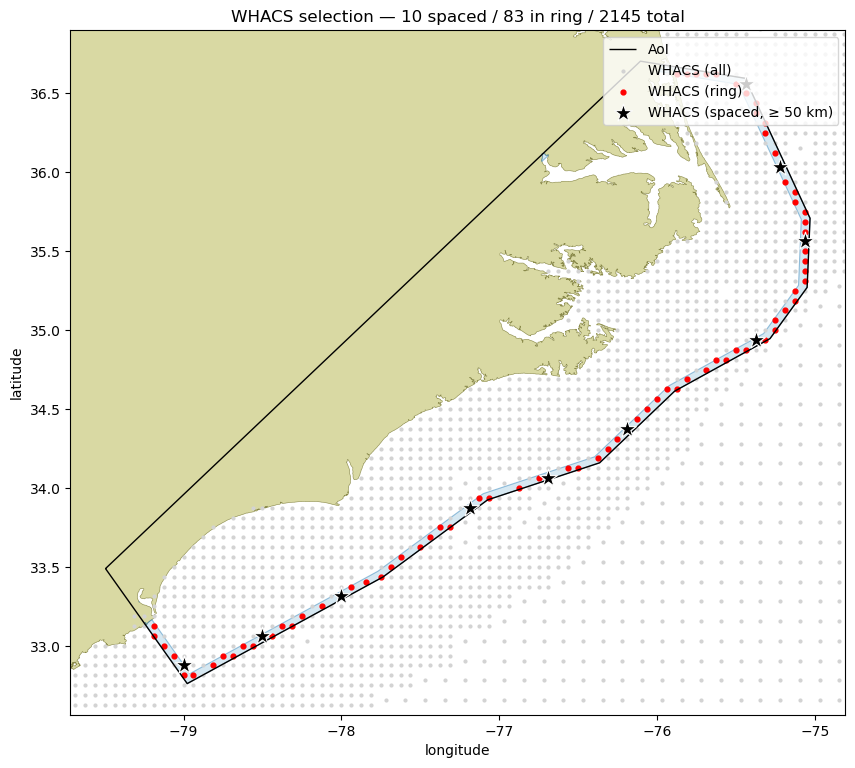

In [16]:
fig, ax = plt.subplots(figsize=(10, 10))

land_gdf.plot(ax=ax, color="#d9d9a3", edgecolor="#8a8a4a", lw=0.4, label="land")
ring_gdf.plot(
    ax=ax,
    facecolor="#a6cee3",
    edgecolor="#1f78b4",
    alpha=0.45,
    lw=0.8,
    label=f"inland ring ({buffer_distance_m:g} m)",
)
aoi_gdf.boundary.plot(ax=ax, color="black", lw=1.0, label="AoI")
whacs_gdf.plot(ax=ax, color="lightgray", markersize=4, label="WHACS (all)")
selected_gdf.plot(ax=ax, color="red", markersize=12, label="WHACS (ring)")
spaced_gdf.plot(
    ax=ax,
    color="black",
    marker="*",
    markersize=180,
    edgecolor="white",
    linewidth=0.8,
    label=f"WHACS (spaced, \u2265 {min_spacing_m / 1000:g} km)",
    zorder=5,
)

minx, miny, maxx, maxy = aoi_gdf.total_bounds
pad_x = 0.05 * (maxx - minx)
pad_y = 0.05 * (maxy - miny)
ax.set_xlim(minx - pad_x, maxx + pad_x)
ax.set_ylim(miny - pad_y, maxy + pad_y)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_aspect("equal")
ax.set_title(
    f"WHACS selection — {len(spaced_gdf)} spaced / {len(selected_gdf)} in ring / {len(whacs_gdf)} total"
)
ax.legend(loc="upper right")
plt.show()

## Save the selection

In [17]:
ring_output_path = resolve("inputs/WHACS/NorthCarolina_whacs_ring.gpkg")

output_path.parent.mkdir(parents=True, exist_ok=True)
selected_gdf.to_file(ring_output_path, driver="GPKG")
spaced_gdf.to_file(output_path, driver="GPKG")

print(
    f"wrote {len(selected_gdf):4d} ring   waypoints to {ring_output_path.relative_to(CASE_DIR)}"
)
print(
    f"wrote {len(spaced_gdf):4d} spaced waypoints to {output_path.relative_to(CASE_DIR)}"
)

wrote   83 ring   waypoints to inputs/WHACS/NorthCarolina_whacs_ring.gpkg
wrote   10 spaced waypoints to inputs/WHACS/NorthCarolina_whacs_selected.gpkg
